<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HancockCNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using device: cpu
Mounted at /content/drive
Rows: 332 | Train: 215 | Validation: 50 | Test: 67
Class counts (train): {0: 123, 1: 92}
Class counts (validation): {0: 29, 1: 21}
Class counts (test): {0: 39, 1: 28}
Original predictor count: 6
Encoded feature count: 19
Automatic class weights: [0.87398374 1.16847826]
SMOTE: False
CNNClassifier(
  (conv): Conv1d(1, 16, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu): ReLU()
  (dropout): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=304, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=16, bias=True)
  (fc3): Linear(in_features=16, out_features=2, bias=True)
)
Epoch 001/500 | train loss=0.6977 | val loss=0.6947 | val ROC-AUC=0.5328 | val PR-AUC=0.5030 | val balanced accuracy=0.5525
Epoch 025/500 | train loss=0.6660 | val loss=0.6702 | val ROC-AUC=0.7348 | val PR-AUC=0.6541 | val balanced accuracy=0.7167
Epoch 050/500 | train loss=0.6008 | val loss=0.6272 | val ROC-AUC=0.7594 | val PR-AUC=0.6734 | val

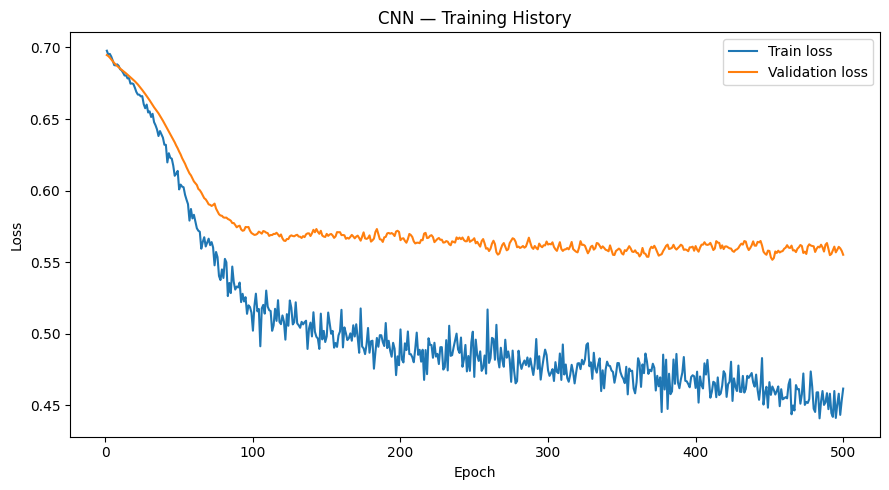


CHECKPOINT: best_val_loss
Checkpoint epoch: 452
Validation-selected threshold: 0.330

TEST METRICS
Checkpoint                      best_val_loss
Checkpoint_Epoch                          452
Validation_Loss                      0.551674
Validation_ROC_AUC                   0.811987
Validation_PR_AUC                    0.789276
Validation_Balanced_Accuracy          0.79064
Threshold                                0.33
Accuracy                             0.716418
Balanced_Accuracy                     0.72619
Precision                            0.628571
Recall                               0.785714
F1                                   0.698413
ROC_AUC                              0.815934
PR_AUC                               0.775881

Confusion matrix:
[[26 13]
 [ 6 22]]

Classification report:
              precision    recall  f1-score   support

           0       0.81      0.67      0.73        39
           1       0.63      0.79      0.70        28

    accuracy                  

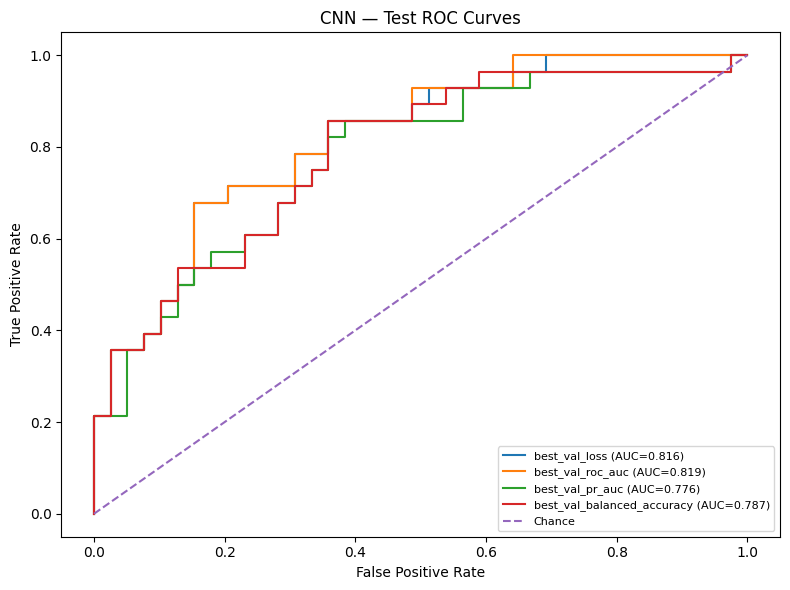

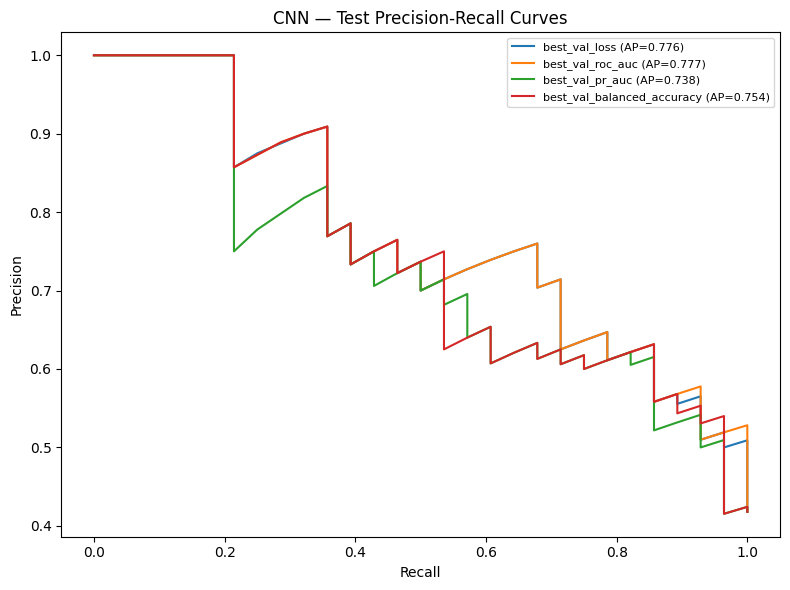


CNN — TEST SET CHECKPOINT COMPARISON
                Checkpoint  Checkpoint_Epoch  Threshold  Accuracy  Balanced_Accuracy  Precision   Recall       F1  ROC_AUC   PR_AUC
             best_val_loss               452      0.330  0.716418           0.726190   0.628571 0.785714 0.698413 0.815934 0.775881
          best_val_roc_auc               457      0.315  0.716418           0.726190   0.628571 0.785714 0.698413 0.818681 0.777115
           best_val_pr_auc               127      0.300  0.716418           0.731227   0.621622 0.821429 0.707692 0.775641 0.737789
best_val_balanced_accuracy               153      0.270  0.716418           0.736264   0.615385 0.857143 0.716418 0.786630 0.754092

Saved results to: /content/drive/MyDrive/CNN_results
Saved checkpoints to: /content/drive/MyDrive/CNN_results/checkpoints

Output files:
 - CNN_epoch_history.csv
 - CNN_results.csv
 - CNN_test_predictions.csv
 - best_cnn_model.pt
 - checkpoint_summary.csv
 - checkpoints
 - cnn_preprocessor.joblib
 - 

In [1]:

# ============================================================
# CNN — HANCOCK HPV CLASSIFIER
# GPT-2-aligned data preparation | Seed 42 | No SMOTE
# Full 500 epochs | Four validation-selected checkpoints
# ============================================================

import os
import json
import random
import copy
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
MAX_EPOCHS = 500
BATCH_SIZE = 32

# ------------------------------------------------------------
# REPRODUCIBILITY AND DEVICE
# ------------------------------------------------------------

def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

drive.mount("/content/drive")


# ============================================================
# 1. LOAD AND PREPARE DATA
# ============================================================

BASE = "/content/drive/MyDrive"
OUT_DIR = os.path.join(BASE, "CNN_results")
CHECKPOINT_DIR = os.path.join(OUT_DIR, "checkpoints")

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)


def load_json_table(path):
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)

    if isinstance(obj, list):
        return pd.DataFrame(obj)

    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if key in obj and isinstance(obj[key], list):
                return pd.DataFrame(obj[key])

        return pd.DataFrame(obj)

    raise ValueError(f"Cannot read table from {path}")


clinical = load_json_table(
    os.path.join(BASE, "clinical_data.json")
)

pathology = load_json_table(
    os.path.join(BASE, "pathological_data.json")
)

if "patient_id" not in clinical.columns:
    raise KeyError("clinical_data.json must contain patient_id.")

if "patient_id" not in pathology.columns:
    raise KeyError("pathological_data.json must contain patient_id.")

# Same left join and suffixes as GPT-2.
df = clinical.merge(
    pathology,
    on="patient_id",
    how="left",
    suffixes=("", "_path")
)

# Same target priority as GPT-2.
target_candidates = [
    "hpv_association_p16",
    "hpv_association_p16_path"
]

target_col = next(
    (c for c in target_candidates if c in df.columns),
    None
)

if target_col is None:
    raise KeyError(
        "HPV target column not found. Checked: "
        f"{target_candidates}"
    )


# Same predictor set and fallback approach as GPT-2.
feature_candidates = {
    "age_at_initial_diagnosis": [
        "age_at_initial_diagnosis"
    ],
    "sex": [
        "sex"
    ],
    "smoking_status": [
        "smoking_status"
    ],
    "primary_tumor_site": [
        "primary_tumor_site"
    ],
    "primarily_metastasis": [
        "primarily_metastasis"
    ],
    "pN_stage": [
        "pN_stage",
        "pN_stage_path",
        "pathological_N_stage",
        "pathological_n_stage"
    ]
}

rename_map = {}

for feature_name, candidates in feature_candidates.items():
    match = next(
        (col for col in candidates if col in df.columns),
        None
    )

    if match is None:
        raise KeyError(
            f"Missing predictor '{feature_name}'. "
            f"Checked columns: {candidates}"
        )

    if match != feature_name:
        rename_map[match] = feature_name

df = df.rename(columns=rename_map)
features = list(feature_candidates.keys())


# ------------------------------------------------------------
# NORMALIZE TARGET LABEL
# ------------------------------------------------------------

def normalize_label(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().lower()

    if value in {"negative", "neg", "0", "false", "no"}:
        return 0

    if value in {"positive", "pos", "1", "true", "yes"}:
        return 1

    try:
        number = float(value)

        if number in (0.0, 1.0):
            return int(number)

    except (ValueError, TypeError):
        pass

    return np.nan


df["HPV_Label"] = df[target_col].map(normalize_label)

df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)

df = df[
    ["patient_id"] + features + ["HPV_Label"]
].copy()


# ============================================================
# 2. STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# Same two-stage stratified split and random_state as GPT-2.
train_val, test = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["HPV_Label"]
)

train, val = train_test_split(
    train_val,
    test_size=0.1875,
    random_state=SEED,
    stratify=train_val["HPV_Label"]
)

train = train.reset_index(drop=True)
val = val.reset_index(drop=True)
test = test.reset_index(drop=True)

print(
    "Rows:", len(df),
    "| Train:", len(train),
    "| Validation:", len(val),
    "| Test:", len(test)
)

print(
    "Class counts (train):",
    train["HPV_Label"].value_counts().sort_index().to_dict()
)

print(
    "Class counts (validation):",
    val["HPV_Label"].value_counts().sort_index().to_dict()
)

print(
    "Class counts (test):",
    test["HPV_Label"].value_counts().sort_index().to_dict()
)


# ============================================================
# 3. IMPUTATION, SCALING AND ONE-HOT ENCODING
# ============================================================

numeric_features = ["age_at_initial_diagnosis"]

categorical_features = [
    c for c in features if c not in numeric_features
]

# Work on copies so the original split dataframes remain unchanged.
X_train_df = train[features].copy()
X_val_df = val[features].copy()
X_test_df = test[features].copy()

# Convert age to numeric and learn its median from training data only.
for frame in [X_train_df, X_val_df, X_test_df]:
    frame["age_at_initial_diagnosis"] = pd.to_numeric(
        frame["age_at_initial_diagnosis"],
        errors="coerce"
    )

age_median = X_train_df["age_at_initial_diagnosis"].median()

if pd.isna(age_median):
    age_median = 0.0

for frame in [X_train_df, X_val_df, X_test_df]:
    frame["age_at_initial_diagnosis"] = (
        frame["age_at_initial_diagnosis"].fillna(age_median)
    )

# Learn categorical modes from training data only.
for col in categorical_features:
    for frame in [X_train_df, X_val_df, X_test_df]:
        frame[col] = frame[col].astype("object")

        frame[col] = frame[col].replace(
            r"^\s*$",
            np.nan,
            regex=True
        )

        frame[col] = frame[col].replace(
            ["nan", "None", "NaN"],
            np.nan
        )

    mode_values = X_train_df[col].mode(dropna=True)

    fill_value = (
        str(mode_values.iloc[0])
        if not mode_values.empty
        else "Unknown"
    )

    for frame in [X_train_df, X_val_df, X_test_df]:
        frame[col] = frame[col].fillna(fill_value).astype(str)

        # Match GPT-2 handling of empty and missing-like strings.
        frame[col] = frame[col].replace(
            ["", "nan", "None", "NaN"],
            "Unknown"
        )

# One-hot encode categories.
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    # Compatibility with older scikit-learn versions.
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

# Scale numeric age and one-hot encode categorical predictors.
preprocessor = ColumnTransformer([
    (
        "num",
        StandardScaler(),
        numeric_features
    ),
    (
        "cat",
        encoder,
        categorical_features
    )
])

# Fit preprocessing on training data only.
X_train = preprocessor.fit_transform(
    X_train_df
).astype(np.float32)

X_val = preprocessor.transform(
    X_val_df
).astype(np.float32)

X_test = preprocessor.transform(
    X_test_df
).astype(np.float32)

y_train = train["HPV_Label"].to_numpy().astype(np.int64)
y_val = val["HPV_Label"].to_numpy().astype(np.int64)
y_test = test["HPV_Label"].to_numpy().astype(np.int64)

print("Original predictor count:", len(features))
print("Encoded feature count:", X_train.shape[1])


# ============================================================
# 4. AUTOMATIC CLASS WEIGHTS — NO SMOTE
# ============================================================

# Inverse-frequency weights calculated from training labels only.
counts = np.bincount(y_train, minlength=2)

if np.any(counts == 0):
    raise ValueError(
        "Both classes must be present in the training set."
    )

weights = len(y_train) / (2.0 * counts)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=device
)

print("Automatic class weights:", weights)
print("SMOTE: False")


# ============================================================
# 5. DATA LOADER AND TENSORS
# ============================================================

train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

X_val_t = torch.tensor(
    X_val,
    dtype=torch.float32,
    device=device
)

y_val_t = torch.tensor(
    y_val,
    dtype=torch.long,
    device=device
)

X_test_t = torch.tensor(
    X_test,
    dtype=torch.float32,
    device=device
)


# ============================================================
# 6. DEFINE CNN ARCHITECTURE
# ============================================================

class CNNClassifier(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.conv = nn.Conv1d(
            in_channels=1,
            out_channels=16,
            kernel_size=3,
            padding=1
        )

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.25)

        self.fc1 = nn.Linear(input_dim * 16, 32)
        self.fc2 = nn.Linear(32, 16)
        self.fc3 = nn.Linear(16, 2)

    def forward(self, x):
        # Input shape: (batch_size, number_of_features)
        # Conv1d input shape: (batch_size, channels, sequence_length)
        x = x.unsqueeze(1)

        x = self.conv(x)
        x = self.relu(x)
        x = self.dropout(x)

        x = x.flatten(start_dim=1)

        x = self.fc1(x)
        x = self.relu(x)

        x = self.fc2(x)
        x = self.relu(x)

        x = self.fc3(x)

        return x


model = CNNClassifier(
    input_dim=X_train.shape[1]
).to(device)

# Use per-example weighted cross entropy.
criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    reduction="none"
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)

print(model)


# ============================================================
# 7. VALIDATION HELPERS AND CHECKPOINT RULES
# ============================================================

thresholds = np.linspace(0.10, 0.90, 161)


def select_threshold(y_true, probabilities):
    """
    Maximize validation balanced accuracy.
    Resolve ties by choosing the threshold closest to 0.5.
    """
    scores = [
        balanced_accuracy_score(
            y_true,
            (probabilities >= threshold).astype(int)
        )
        for threshold in thresholds
    ]

    max_score = max(scores)

    best_threshold = min(
        (
            threshold
            for threshold, score in zip(thresholds, scores)
            if np.isclose(score, max_score)
        ),
        key=lambda threshold: abs(threshold - 0.5)
    )

    return float(best_threshold), float(max_score)


def predict_probabilities(model, X_tensor):
    model.eval()

    with torch.no_grad():
        probabilities = torch.softmax(
            model(X_tensor),
            dim=1
        )[:, 1].cpu().numpy()

    return probabilities


def validation_metrics(model):
    probabilities = predict_probabilities(model, X_val_t)

    threshold, balanced_acc = select_threshold(
        y_val,
        probabilities
    )

    if len(np.unique(y_val)) == 2:
        roc_auc = roc_auc_score(y_val, probabilities)
    else:
        roc_auc = np.nan

    pr_auc = average_precision_score(
        y_val,
        probabilities
    )

    return {
        "probabilities": probabilities,
        "threshold": threshold,
        "balanced_accuracy": float(balanced_acc),
        "roc_auc": float(roc_auc),
        "pr_auc": float(pr_auc)
    }


checkpoint_specs = {
    "best_val_loss": {
        "filename": "cnn_best_val_loss.pt"
    },
    "best_val_roc_auc": {
        "filename": "cnn_best_val_roc_auc.pt"
    },
    "best_val_pr_auc": {
        "filename": "cnn_best_val_pr_auc.pt"
    },
    "best_val_balanced_accuracy": {
        "filename": "cnn_best_val_balanced_accuracy.pt"
    }
}

best_values = {
    "best_val_loss": float("inf"),
    "best_val_roc_auc": -float("inf"),
    "best_val_pr_auc": -float("inf"),
    "best_val_balanced_accuracy": -float("inf")
}

best_epochs = {}
history = []


def save_checkpoint(checkpoint_name, epoch, val_loss, val_results):
    """Save a checkpoint with its validation metrics."""
    checkpoint = {
        "model_state_dict": copy.deepcopy(model.state_dict()),
        "epoch": int(epoch),
        "validation_loss": float(val_loss),
        "validation_roc_auc": float(val_results["roc_auc"]),
        "validation_pr_auc": float(val_results["pr_auc"]),
        "validation_balanced_accuracy": float(
            val_results["balanced_accuracy"]
        ),
        "validation_threshold": float(val_results["threshold"])
    }

    torch.save(
        checkpoint,
        os.path.join(
            CHECKPOINT_DIR,
            checkpoint_specs[checkpoint_name]["filename"]
        )
    )


# ============================================================
# 8. TRAIN FOR ALL 500 EPOCHS — NO EARLY STOPPING
# ============================================================

for epoch in range(1, MAX_EPOCHS + 1):

    model.train()

    running_loss = 0.0
    seen = 0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        logits = model(xb)

        per_example_loss = criterion(logits, yb)
        loss = per_example_loss.mean()

        loss.backward()
        optimizer.step()

        running_loss += per_example_loss.detach().sum().item()
        seen += len(yb)

    train_loss = running_loss / max(seen, 1)

    # Evaluate validation loss and metrics after this epoch.
    model.eval()

    with torch.no_grad():
        val_logits = model(X_val_t)
        val_loss = criterion(val_logits, y_val_t).mean().item()

    val_results = validation_metrics(model)

    history.append({
        "epoch": epoch,
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "val_roc_auc": val_results["roc_auc"],
        "val_pr_auc": val_results["pr_auc"],
        "val_balanced_accuracy": val_results["balanced_accuracy"],
        "val_threshold": val_results["threshold"]
    })

    # Checkpoint 1: lowest validation loss.
    if val_loss < best_values["best_val_loss"]:
        best_values["best_val_loss"] = float(val_loss)
        best_epochs["best_val_loss"] = epoch

        save_checkpoint(
            "best_val_loss",
            epoch,
            val_loss,
            val_results
        )

    # Checkpoint 2: highest validation ROC-AUC.
    roc_auc = val_results["roc_auc"]

    if np.isfinite(roc_auc) and (
        roc_auc > best_values["best_val_roc_auc"]
    ):
        best_values["best_val_roc_auc"] = float(roc_auc)
        best_epochs["best_val_roc_auc"] = epoch

        save_checkpoint(
            "best_val_roc_auc",
            epoch,
            val_loss,
            val_results
        )

    # Checkpoint 3: highest validation PR-AUC.
    pr_auc = val_results["pr_auc"]

    if np.isfinite(pr_auc) and (
        pr_auc > best_values["best_val_pr_auc"]
    ):
        best_values["best_val_pr_auc"] = float(pr_auc)
        best_epochs["best_val_pr_auc"] = epoch

        save_checkpoint(
            "best_val_pr_auc",
            epoch,
            val_loss,
            val_results
        )

    # Checkpoint 4: highest validation balanced accuracy.
    balanced_acc = val_results["balanced_accuracy"]

    if balanced_acc > best_values["best_val_balanced_accuracy"]:
        best_values["best_val_balanced_accuracy"] = float(
            balanced_acc
        )
        best_epochs["best_val_balanced_accuracy"] = epoch

        save_checkpoint(
            "best_val_balanced_accuracy",
            epoch,
            val_loss,
            val_results
        )

    if epoch == 1 or epoch % 25 == 0:
        print(
            f"Epoch {epoch:03d}/{MAX_EPOCHS} | "
            f"train loss={train_loss:.4f} | "
            f"val loss={val_loss:.4f} | "
            f"val ROC-AUC={val_results['roc_auc']:.4f} | "
            f"val PR-AUC={val_results['pr_auc']:.4f} | "
            f"val balanced accuracy={balanced_acc:.4f}"
        )

# There is deliberately no early-stopping condition.
if len(history) != MAX_EPOCHS:
    raise RuntimeError(
        f"Expected {MAX_EPOCHS} epochs, but ran {len(history)}."
    )

print(f"\nTraining completed: {len(history)} epochs.")
print("Best checkpoint epochs:", best_epochs)

history_df = pd.DataFrame(history)

history_df.to_csv(
    os.path.join(OUT_DIR, "training_history.csv"),
    index=False
)


# ============================================================
# 9. PLOT TRAINING HISTORY
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN — Training History")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "training_history.png"),
    dpi=150
)

plt.show()


# ============================================================
# 10. EVALUATE ALL FOUR CHECKPOINTS ON THE TEST SET
# ============================================================

# Checkpoints are chosen using validation data only.
# Each threshold is selected from validation probabilities only.
# The test set is used only for final evaluation.

all_test_metrics = []
all_test_predictions = []
checkpoint_summary = []

for checkpoint_name, spec in checkpoint_specs.items():

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        spec["filename"]
    )

    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False
        )
    except TypeError:
        # Compatibility with older PyTorch versions.
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device
        )

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    val_prob = predict_probabilities(model, X_val_t)
    test_prob = predict_probabilities(model, X_test_t)

    # Select threshold using validation data for this checkpoint.
    best_threshold, val_bal_acc = select_threshold(
        y_val,
        val_prob
    )

    test_pred = (
        test_prob >= best_threshold
    ).astype(int)

    test_roc_auc = (
        roc_auc_score(y_test, test_prob)
        if len(np.unique(y_test)) == 2
        else np.nan
    )

    test_pr_auc = average_precision_score(
        y_test,
        test_prob
    )

    metrics = {
        "Checkpoint": checkpoint_name,
        "Checkpoint_Epoch": int(checkpoint["epoch"]),
        "Validation_Loss": float(checkpoint["validation_loss"]),
        "Validation_ROC_AUC": float(checkpoint["validation_roc_auc"]),
        "Validation_PR_AUC": float(checkpoint["validation_pr_auc"]),
        "Validation_Balanced_Accuracy": float(val_bal_acc),
        "Threshold": float(best_threshold),
        "Accuracy": accuracy_score(y_test, test_pred),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_test,
            test_pred
        ),
        "Precision": precision_score(
            y_test,
            test_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            test_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_test,
            test_pred,
            zero_division=0
        ),
        "ROC_AUC": test_roc_auc,
        "PR_AUC": test_pr_auc
    }

    all_test_metrics.append(metrics)

    predictions_df = pd.DataFrame({
        "patient_id": test["patient_id"].to_numpy(),
        "y_true": y_test,
        "probability_positive": test_prob,
        "prediction": test_pred,
        "checkpoint": checkpoint_name,
        "checkpoint_epoch": int(checkpoint["epoch"]),
        "threshold": float(best_threshold)
    })

    all_test_predictions.append(predictions_df)

    checkpoint_summary.append({
        "Checkpoint": checkpoint_name,
        "Epoch": int(checkpoint["epoch"]),
        "Validation_Loss": float(checkpoint["validation_loss"]),
        "Validation_ROC_AUC": float(checkpoint["validation_roc_auc"]),
        "Validation_PR_AUC": float(checkpoint["validation_pr_auc"]),
        "Validation_Balanced_Accuracy": float(val_bal_acc),
        "Threshold": float(best_threshold)
    })

    print("\n" + "=" * 65)
    print("CHECKPOINT:", checkpoint_name)
    print("Checkpoint epoch:", checkpoint["epoch"])
    print(f"Validation-selected threshold: {best_threshold:.3f}")

    print("\nTEST METRICS")
    print(pd.Series(metrics).to_string())

    print("\nConfusion matrix:")
    print(confusion_matrix(y_test, test_pred))

    print("\nClassification report:")
    print(
        classification_report(
            y_test,
            test_pred,
            zero_division=0
        )
    )


# Save metrics and predictions for all four checkpoints.
metrics_df = pd.DataFrame(all_test_metrics)

metrics_df.to_csv(
    os.path.join(OUT_DIR, "metrics_all_checkpoints.csv"),
    index=False
)

predictions_df = pd.concat(
    all_test_predictions,
    ignore_index=True
)

predictions_df.to_csv(
    os.path.join(OUT_DIR, "test_predictions_all_checkpoints.csv"),
    index=False
)

checkpoint_summary_df = pd.DataFrame(checkpoint_summary)

checkpoint_summary_df.to_csv(
    os.path.join(OUT_DIR, "checkpoint_summary.csv"),
    index=False
)


# ============================================================
# 11. TEST ROC CURVES FOR ALL FOUR CHECKPOINTS
# ============================================================

plt.figure(figsize=(8, 6))

for checkpoint_name, spec in checkpoint_specs.items():

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        spec["filename"]
    )

    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False
        )
    except TypeError:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device
        )

    model.load_state_dict(checkpoint["model_state_dict"])

    test_prob = predict_probabilities(model, X_test_t)

    if len(np.unique(y_test)) == 2:
        fpr, tpr, _ = roc_curve(y_test, test_prob)
        auc_value = roc_auc_score(y_test, test_prob)

        plt.plot(
            fpr,
            tpr,
            label=f"{checkpoint_name} (AUC={auc_value:.3f})"
        )

plt.plot([0, 1], [0, 1], "--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("CNN — Test ROC Curves")
plt.legend(fontsize=8)
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "roc_curves_all_checkpoints.png"),
    dpi=150
)

plt.show()


# ============================================================
# 12. TEST PRECISION-RECALL CURVES FOR ALL CHECKPOINTS
# ============================================================

plt.figure(figsize=(8, 6))

for checkpoint_name, spec in checkpoint_specs.items():

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        spec["filename"]
    )

    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False
        )
    except TypeError:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device
        )

    model.load_state_dict(checkpoint["model_state_dict"])

    test_prob = predict_probabilities(model, X_test_t)

    precision, recall, _ = precision_recall_curve(
        y_test,
        test_prob
    )

    ap_value = average_precision_score(
        y_test,
        test_prob
    )

    plt.plot(
        recall,
        precision,
        label=f"{checkpoint_name} (AP={ap_value:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("CNN — Test Precision-Recall Curves")
plt.legend(fontsize=8)
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "pr_curves_all_checkpoints.png"),
    dpi=150
)

plt.show()


# ============================================================
# 13. SAVE PREPROCESSOR AND SETTINGS
# ============================================================

joblib.dump(
    preprocessor,
    os.path.join(OUT_DIR, "cnn_preprocessor.joblib")
)

settings = {
    "model": "CNN",
    "seed": SEED,
    "features": features,
    "target_column": target_col,
    "class_weights": weights.tolist(),
    "smote": False,
    "early_stopping": False,
    "max_epochs": MAX_EPOCHS,
    "epochs_run": len(history),
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": 0.0001,
    "weight_decay": 0.0001,
    "train_size": len(train),
    "validation_size": len(val),
    "test_size": len(test),
    "split": {
        "train": len(train),
        "validation": len(val),
        "test": len(test)
    },
    "checkpoint_epochs": {
        key: int(value)
        for key, value in best_epochs.items()
    },
    "checkpoint_files": {
        key: spec["filename"]
        for key, spec in checkpoint_specs.items()
    },
    "threshold_selection": (
        "Maximize validation balanced accuracy; "
        "ties resolved by choosing the threshold closest to 0.5"
    ),
    "test_used_for_model_selection": False
}

with open(
    os.path.join(OUT_DIR, "settings.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(settings, f, indent=2)


# ============================================================
# 14. FINAL CHECKPOINT COMPARISON
# ============================================================

display_columns = [
    "Checkpoint",
    "Checkpoint_Epoch",
    "Threshold",
    "Accuracy",
    "Balanced_Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]

print("\n" + "=" * 80)
print("CNN — TEST SET CHECKPOINT COMPARISON")
print("=" * 80)

print(
    metrics_df[display_columns].to_string(index=False)
)

print("\nSaved results to:", OUT_DIR)
print("Saved checkpoints to:", CHECKPOINT_DIR)

print("\nOutput files:")
for filename in sorted(os.listdir(OUT_DIR)):
    print(" -", filename)

print("\nCheckpoint files:")
for filename in sorted(os.listdir(CHECKPOINT_DIR)):
    print(" -", filename)
